# Accessing External Data - CDSE - Sentinel-2

Accessing CDSE Data with the Pangeo Stack


In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pystac_client
import stackstac
import xarray as xr
from shapely.geometry import box


# Start a cluster

In [19]:
# from dask.distributed import Client
# from dask_gateway import Gateway
# gateway = Gateway()
# cluster = gateway.new_cluster()
# cluster.scale(4)
# client = cluster.get_client()
# client

## AOE: Almería coast, southern Spain

A smaller coastal box near Almería, chosen inside a single Sentinel-2 tile.


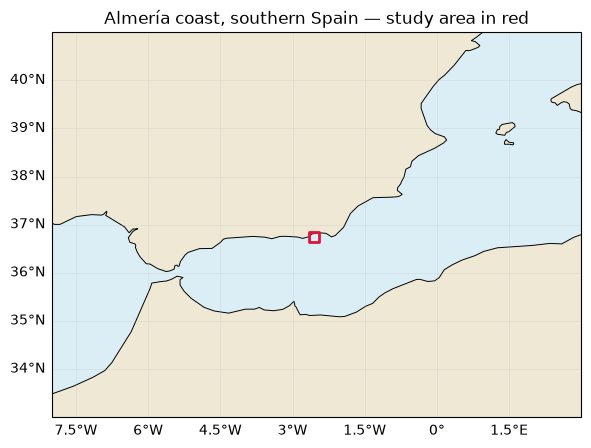

In [20]:
roi_bounds = (-2.65, 36.65, -2.45, 36.85)  # Almería coast: west, south, east, north

fig, ax = plt.subplots(figsize=(8, 5), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([-8, 3, 33, 41])  # Zoom out for southern Spain and North Africa
ax.set_facecolor("#dbeef5")

ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#eee8d5")
ax.coastlines("50m", linewidth=0.7)
ax.add_geometries([box(*roi_bounds)], ccrs.PlateCarree(), facecolor="none", edgecolor="crimson", linewidth=2)
ax.gridlines(draw_labels=["bottom", "left"], linewidth=0.4, alpha=0.3)
ax.set_title("Almería coast, southern Spain — study area in red");


## S3 Credentials

taken from:
https://documentation.dataspace.copernicus.eu/notebook-samples/geo/stac_ndvi.html

In order to access the data from CloudFerro's catalog, authentication is required. To facilitate this, you will need to create an account in the Copernicus Data Space Ecosystem (CDSE). The registration process is quick and can be completed in under 60 seconds. You can find the registration link here: https://documentation.dataspace.copernicus.eu/APIs/S3.html.

Once you have created an account, the same URL will redirect you to the section where you can generate your `S3 Credentials`. To do this, simply click the `Add Credential` button. This will allow you to define an expiration date for your credentials.

After selecting the expiration date, you will have successfully created your own S3 credentials. Please make sure to save the secret key at this point, as it will not be displayed again.

Now that you have your S3 credentials, you can use them to connect to the STAC catalog. By utilizing the `os` package, you will set environment variables to authenticate yourself as a valid user for the S3 protocol.

The only variables you need to configure are:
* `CDSE_S3_ACCESS_KEY`
* `CDSE_S3_SECRET_KEY`.

In [21]:
# os.environ["CDSE_S3_ACCESS_KEY"] = "CDSE_S3_ACCESS_KEY" # Replace with your keys!
# os.environ["CDSE_S3_SECRET_KEY"] = "CDSE_S3_SECRET_KEY" # Replace with your keys!

# or create a .env file with those two variables above and run this instead 
with open(".env") as f:
    for line in f:
        key, value = line.strip().split("=", 1)
        os.environ[key] = value

In [22]:
os.environ["GDAL_HTTP_TCP_KEEPALIVE"] = "YES"
os.environ["AWS_S3_ENDPOINT"] = "eodata.dataspace.copernicus.eu"
os.environ["AWS_ACCESS_KEY_ID"] = os.environ.get("CDSE_S3_ACCESS_KEY")
os.environ["AWS_SECRET_ACCESS_KEY"] = os.environ.get("CDSE_S3_SECRET_KEY")
os.environ["AWS_HTTPS"] = "YES"
os.environ["AWS_VIRTUAL_HOSTING"] = "FALSE"
os.environ["GDAL_HTTP_UNSAFESSL"] = "YES"

## Connecting to the STAC Catalog

We connect to the Copernicus STAC catalog, available at the endpoint: https://stac.dataspace.copernicus.eu/v1.

In [ ]:
URL = "https://stac.dataspace.copernicus.eu/v1"
cat = pystac_client.Client.open(URL)

## Open the daily cube for this area


In [24]:
daily_surface_cube = xr.open_zarr(
    "https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/med_cubes/ocean-med-daily-surface-cube.zarr",
    group="0", chunks={}, consolidated=True, decode_coords="all",
)

surface_region = daily_surface_cube.sel(
    lon=slice(roi_bounds[0], roi_bounds[2]),
    lat=slice(roi_bounds[1], roi_bounds[3]),
)

daily_surface_cube

<xarray.Dataset> Size: 157GB
Dimensions:                          (time: 2557, lat: 378, lon: 1012)
Coordinates:
  * time                             (time) datetime64[ns] 20kB 2016-01-01 .....
  * lat                              (lat) float32 2kB 30.27 30.31 ... 45.98
  * lon                              (lon) float32 4kB -6.062 -6.021 ... 36.06
    spatial_ref                      int64 8B ...
Data variables: (12/22)
    adt_4dvarnet                     (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    adt_4dvarnet_ssh                 (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    category                         (time, lat, lon) float32 4GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    dos                              (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    dos_error                        (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    fsle                             (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    ...                               ...
    ugosa_4dvarnet_ssh               (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    vgos_4dvarnet                    (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    vgos_4dvarnet_ssh                (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    vgosa_4dvarnet                   (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    vgosa_4dvarnet_ssh               (time, lat, lon) float64 8GB dask.array<chunksize=(1, 189, 506), meta=np.ndarray>
    water_mask                       (lat, lon) uint8 383kB dask.array<chunksize=(189, 506), meta=np.ndarray>
Attributes: (12/15)
    title:                   Mediterranean grid
    grid_resolution:         1/24 degree
    geospatial_lat_min:      30.27083396911621
    geospatial_lat_max:      45.97916793823242
    geospatial_lon_min:      -6.062498092651367
    geospatial_lon_max:      36.0625
    ...                      ...
    spatial:dimensions:      ['lat', 'lon']
    spatial:bbox:            [-6.083331425041402, 30.250000634939664, 36.0833...
    spatial:transform_type:  affine
    spatial:shape:           [378, 1012]
    spatial:registration:    pixel
    zarr_conventions:        [{'uuid': 'f17cb550-5864-4468-aeb7-f3180cfb622f'...

In [47]:
params = {
    "max_items": 12,
    "collections": "sentinel-2-l2a",
    "datetime": "2017-06-01/2017-12-31",
    "bbox": roi_bounds,
    "query": {"eo:cloud_cover": {"lte": 20}},
    "sortby": "properties.eo:cloud_cover",  # Least cloudy scenes first
}


## Select six scenes

Take the six least cloudy scenes for this smaller box in July–August 2017.


In [48]:
items = list(cat.search(**params).items_as_dicts())


## Creating DataCube from STAC

After performing the search, we can create a STACK object from the obtained items. In the definition of the STACK object, the following parameters must be declared:

* `items`: The STAC items that will be included in the stack object.
* `resolution`: The desired output resolution.
* `bounds_latlon`: The spatial bounding box of the output, given in degrees of latitude and longitude.
* `chunksize`: The chunk size to be used for the Dask array.
* `epsg`: The EPSG code for the coordinate reference system to which the data will be reprojected.
* `gdal_env`: GDAL configuration options to be used when opening and reading the datasets.

*note: added a workaround for compatibility reasons*

In [49]:
# Temporary compatibility wrappers for stackstac 0.5.0 / NumPy 2 / pandas 3.
from unittest.mock import patch

_can_cast, _to_datetime = np.can_cast, pd.to_datetime
with (
    patch(
        "numpy.can_cast",
        lambda from_, to, casting="safe": _can_cast(np.result_type(from_), to, casting),
    ),
    patch(
        "pandas.to_datetime",
        lambda *args, infer_datetime_format=None, **kwargs: _to_datetime(*args, **kwargs),
    ),
):
    stack = stackstac.stack(
        items=items,
        sortby_date=False,  # Keep least-cloudy scenes first
        rescale=False,  # Raw DN: 0 is nodata; apply the N0500 offset below
        assets=["B04_20m", "B03_20m", "B02_20m", "B05_20m"],  # RGB + red edge for NDCI
        resolution=1 / 1200,  # Small-area RGB preview (degrees)
        bounds_latlon=roi_bounds,
        chunksize=512,
        xy_coords="center",
        epsg=4326,
        gdal_env=stackstac.DEFAULT_GDAL_ENV.updated(
            {
                "GDAL_NUM_THREADS": -1,
                "GDAL_HTTP_UNSAFESSL": "YES",
                "GDAL_HTTP_TCP_KEEPALIVE": "YES",
                "AWS_VIRTUAL_HOSTING": "FALSE",
                "AWS_HTTPS": "YES",
            }
        ),
    )

stack = stack.where(stack > 0)  # Mask no-data pixels


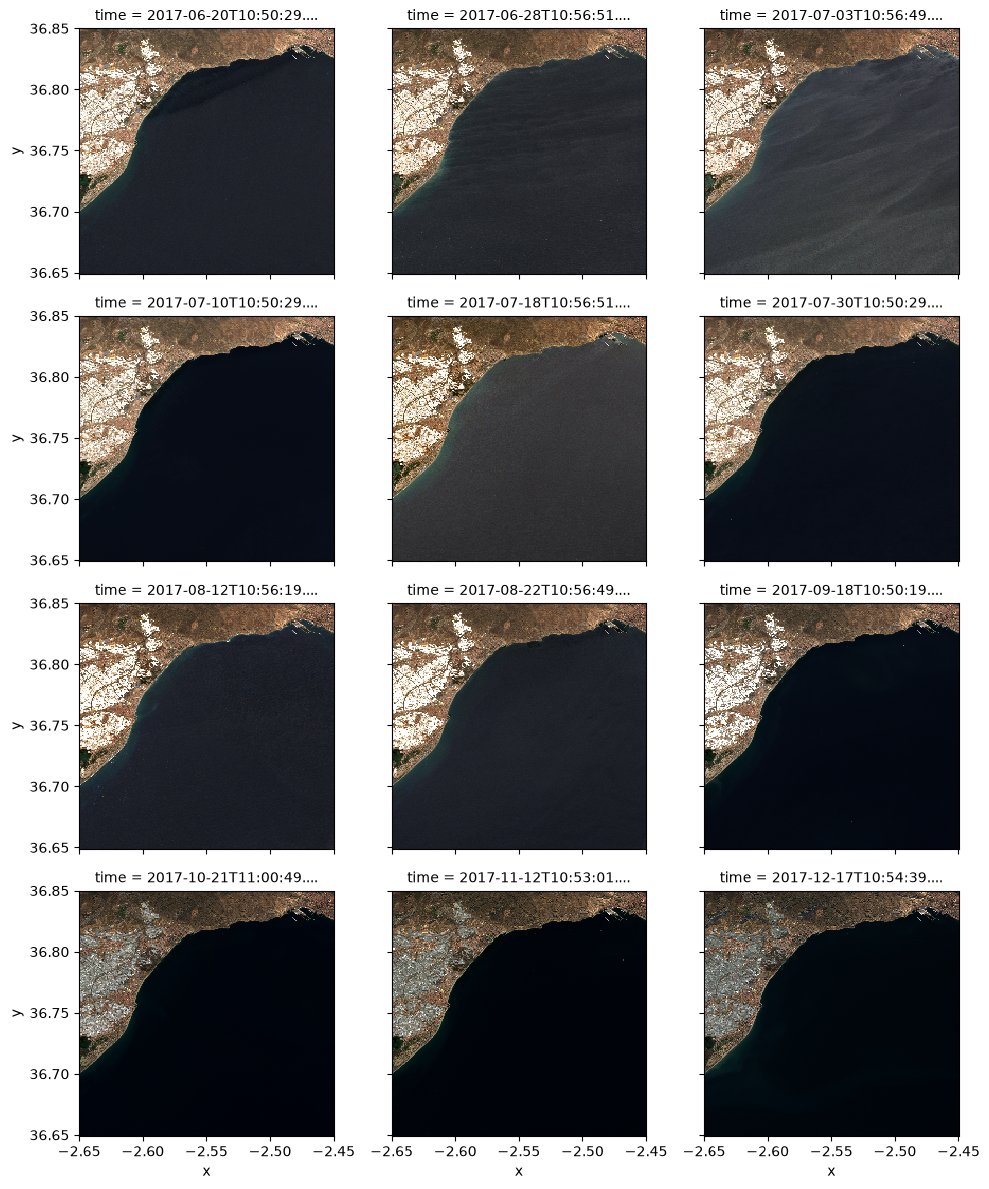

In [50]:
stack = stack.sortby("time").compute()
rgb = stack.sel(band=["B04_20m", "B03_20m", "B02_20m"])
rgb.plot.imshow(rgb="band", col="time", col_wrap=3, robust=True, size=3)


## Overlay the first displayed date and salinity


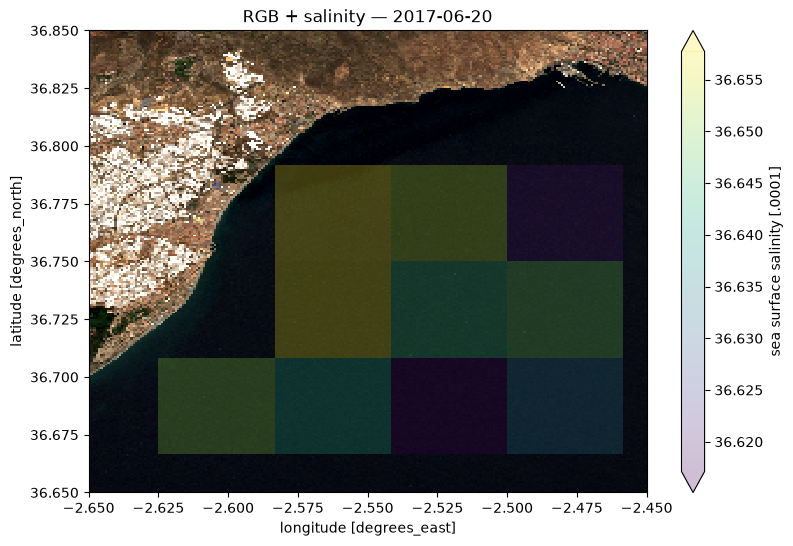

In [51]:
selected_day = str(stack.time.values[0])[:10]
ax = rgb.isel(time=0).plot.imshow(rgb="band", robust=True, figsize=(9, 6)).axes
surface_region.sos.sel(time=selected_day).plot(ax=ax, cmap="viridis", alpha=0.25, robust=True)
ax.set(xlim=(roi_bounds[0], roi_bounds[2]), ylim=(roi_bounds[1], roi_bounds[3]), title=f"RGB + salinity — {selected_day}");


## Compare NDCI and salinity over time

**NDCI (Normalized Difference Chlorophyll Index)** uses red-edge and red reflectance:

`NDCI = (B05 - B04) / (B05 + B04)`

Compare its daily mean with salinity (`sos`) over the same ocean pixels. NDCI is a relative chlorophyll-sensitive index, not chlorophyll concentration; it was developed for productive, turbid coastal waters and is less informative in clear, low-chlorophyll water ([original paper](https://doi.org/10.1016/j.rse.2011.10.016)).


In [52]:
bands = stack.assign_coords(time=stack.time.dt.floor("D")) - 1000  # N0500 offset; scale cancels
bands = bands.where(bands >= 0)  # Exclude negative reflectance and no-data pixels
red, red_edge = bands.sel(band="B04_20m", drop=True), bands.sel(band="B05_20m", drop=True)
ndci = (red_edge - red) / (red_edge + red).where(red_edge + red > 0)
ndci


<xarray.DataArray 'stackstac-737eabe56a5115ee2d68bc24faa47dac' (time: 12,
                                                                y: 241, x: 240)> Size: 6MB
array([[[ 1.05029971e-01,  1.32213294e-01,  1.16234847e-01, ...,
          6.68286756e-02,  3.35537595e-02, -3.76196990e-03],
        [ 7.78489614e-02,  5.55059789e-02,  7.35751295e-02, ...,
          8.23529412e-02,  8.32509393e-02,  1.33359103e-01],
        [ 9.08488064e-02,  9.17667238e-02,  5.86398334e-02, ...,
          6.71577123e-02,  6.07516248e-02,  7.08542714e-02],
        ...,
        [-1.02135562e-02,  8.65842055e-02,  3.45508391e-02, ...,
          4.29988975e-02,  3.81355932e-02, -2.77511962e-02],
        [ 4.90490490e-02,  2.01729107e-02,  6.42927794e-02, ...,
          3.38818974e-02,  1.37275607e-02,  7.05645161e-02],
        [-2.91079812e-02,  2.29885057e-02,  4.79041916e-02, ...,
          3.61904762e-02,  2.02117421e-02,  2.04081633e-02]],

       [[ 1.05194805e-01,  1.03089630e-01,  1.06503834e-01, ...,
          8.69155946e-02,  2.44404425e-02,  2.33553912e-02],
        [ 9.25844669e-02,  6.80100756e-02,  7.85314855e-02, ...,
          1.04849279e-01,  8.33333333e-02,  9.45273632e-02],
        [ 8.66372981e-02,  9.68766543e-02,  5.87741394e-02, ...,
          7.49931824e-02,  9.58230958e-02,  6.89145223e-02],
...
         -7.33333333e-01, -6.80000000e-01, -1.00000000e+00],
        [-4.21052632e-01, -3.60000000e-01, -2.45901639e-01, ...,
         -7.93103448e-01, -7.36842105e-01, -9.16666667e-01],
        [-7.20000000e-01, -8.09523810e-01,             nan, ...,
         -7.14285714e-01, -9.16666667e-01, -1.00000000e+00]],

       [[ 1.44479495e-01,  1.44246353e-01,  1.48028962e-01, ...,
          1.81240840e-01,  7.29579699e-02,  1.15810675e-01],
        [ 1.01576182e-01,  8.41049383e-02,  8.64440079e-02, ...,
          9.03747245e-02,  1.56599553e-01,  1.38009050e-01],
        [ 1.03098592e-01,  1.24779074e-01,  4.02184707e-02, ...,
          7.71169355e-02,  6.15188799e-02, -9.50118765e-03],
        ...,
        [-8.62068966e-01, -3.53846154e-01, -3.50649351e-01, ...,
         -3.20000000e-01, -5.90909091e-01, -5.83333333e-01],
        [-3.84615385e-01, -6.52173913e-02, -5.00000000e-01, ...,
         -6.60377358e-01, -3.68421053e-01, -6.15384615e-01],
        [-7.46031746e-01, -6.14035088e-01, -1.76470588e-01, ...,
         -5.92592593e-01, -5.91836735e-01, -5.83333333e-01]]],
      shape=(12, 241, 240))
Coordinates: (12/53)
  * time                                   (time) datetime64[us] 96B 2017-06-...
    id                                     (time) <U60 3kB 'S2B_MSIL2A_201706...
    eopf:origin_datetime                   (time) <U27 1kB '2024-04-15T01:05:...
    sat:platform_international_designator  (time) <U9 432B '2017-013A' ... '2...
    view:incidence_angle                   (time) float64 96B 7.239 ... 7.245
    created                                (time) <U27 1kB '2024-04-15T01:05:...
    ...                                     ...
    proj:code                              <U10 40B 'EPSG:32630'
    proj:shape                             object 8B {5490}
    nodata                                 int64 8B 0
    auth:refs                              <U2 8B 's3'
    storage:refs                           object 8B {'cdse-s3', 'creodias-s3'}
    epsg                                   int64 8B 4326
Attributes:
    spec:        RasterSpec(epsg=4326, bounds=(-2.6500000000000004, 36.649166...
    crs:         epsg:4326
    transform:   | 0.00, 0.00,-2.65|\n| 0.00,-0.00, 36.85|\n| 0.00, 0.00, 1.00|
    resolution:  0.0008333333333333334

In [53]:
salinity = surface_region.sos.sel(time=bands.time).interp(lon=bands.x, lat=bands.y, method="nearest")
water = xr.Dataset({"NDCI": ndci, "salinity": salinity}).where(ndci.notnull() & salinity.notnull())
water

<xarray.Dataset> Size: 11MB
Dimensions:                                (time: 12, y: 241, x: 240)
Coordinates: (12/56)
  * time                                   (time) datetime64[us] 96B 2017-06-...
    id                                     (time) <U60 3kB 'S2B_MSIL2A_201706...
    eopf:origin_datetime                   (time) <U27 1kB '2024-04-15T01:05:...
    sat:platform_international_designator  (time) <U9 432B '2017-013A' ... '2...
    view:incidence_angle                   (time) float64 96B 7.239 ... 7.245
    created                                (time) <U27 1kB '2024-04-15T01:05:...
    ...                                     ...
    proj:shape                             object 8B {5490}
    nodata                                 int64 8B 0
    auth:refs                              <U2 8B 's3'
    storage:refs                           object 8B {'cdse-s3', 'creodias-s3'}
    epsg                                   int64 8B 4326
    spatial_ref                            int64 8B ...
Data variables:
    NDCI                                   (time, y, x) float64 6MB dask.array<chunksize=(1, 241, 240), meta=np.ndarray>
    salinity                               (time, y, x) float64 6MB dask.array<chunksize=(1, 241, 240), meta=np.ndarray>

In [56]:
series = water.mean(("x", "y")).compute().to_dataframe()[["NDCI", "salinity"]]
series


,NDCI,salinity
time,,
2017-06-20,0.020044,36.645897
2017-06-28,0.012583,36.548347
2017-07-03,0.006183,36.504507
2017-07-10,-0.024014,36.640182
2017-07-18,0.019475,36.779604
2017-07-30,-0.023747,36.822089
2017-08-12,0.007783,36.882701
2017-08-22,0.010050,36.889967
2017-09-18,-0.045077,36.497550


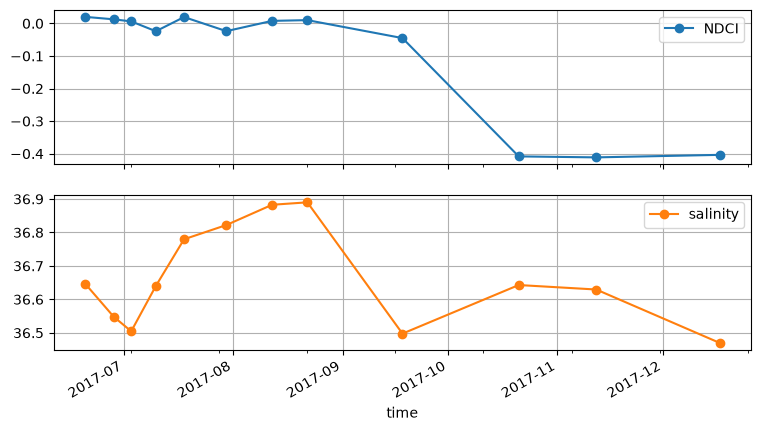

In [57]:
series.plot(subplots=True, marker="o", figsize=(9, 5), grid=True);  # Separate scales, shared dates
